<a href="https://colab.research.google.com/github/Manawariqbal/Data-Analysis-Projects/blob/main/Retail_Sales_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
"""
1. Retail Sales Analysis (retail_sales.csv, 1,008 rows)
Question: “Which products, regions, and months drive the most revenue?”

Remove the 8 duplicate orders and fill the missing customer ages.
Create a revenue column from quantity, unit price, and discount.
Plot monthly revenue as a line chart and find the best-selling category.
Show revenue by region and category in a seaborn heatmap.
Compare payment methods with a count plot.
Write a short note on what happens in Nov and Dec.
"""


'\n1. Retail Sales Analysis (retail_sales.csv, 1,008 rows)\nQuestion: “Which products, regions, and months drive the most revenue?”\n\nRemove the 8 duplicate orders and fill the missing customer ages.\nCreate a revenue column from quantity, unit price, and discount.\nPlot monthly revenue as a line chart and find the best-selling category.\nShow revenue by region and category in a seaborn heatmap.\nCompare payment methods with a count plot.\nWrite a short note on what happens in Nov and Dec.\n'

In [32]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
df=pd.read_csv('/content/retail_sales.csv')
df.isna().sum()
df=df.drop_duplicates().reset_index(drop=True)

In [33]:
#Task 1

df["customer_age"]=df["customer_age"].fillna(df["customer_age"].median())

In [34]:
df.isna().sum()
df["date"]=pd.to_datetime(df["date"])

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        1000 non-null   int64         
 1   date            1000 non-null   datetime64[ns]
 2   category        1000 non-null   object        
 3   region          1000 non-null   object        
 4   quantity        1000 non-null   int64         
 5   unit_price      1000 non-null   float64       
 6   discount_pct    1000 non-null   int64         
 7   customer_age    1000 non-null   float64       
 8   payment_method  1000 non-null   object        
dtypes: datetime64[ns](1), float64(2), int64(3), object(3)
memory usage: 70.4+ KB


In [36]:
df

,order_id,date,category,region,quantity,unit_price,discount_pct,customer_age,payment_method
0,1001,2025-12-11,Clothing,South,4,54.79,0,37.0,Wallet
1,1002,2025-08-17,Home,East,2,90.48,10,18.0,UPI
2,1003,2025-09-07,Home,South,5,71.28,15,30.0,Cash
3,1004,2025-11-24,Groceries,West,4,12.18,5,24.0,UPI
4,1005,2025-07-31,Home,South,2,107.08,20,36.0,Card
...,...,...,...,...,...,...,...,...,...
995,1996,2025-04-25,Home,South,2,80.26,0,27.0,UPI
996,1997,2025-07-17,Electronics,North,2,374.52,0,27.0,Card
997,1998,2025-06-30,Clothing,North,4,42.64,0,62.0,Wallet
998,1999,2025-01-28,Groceries,West,4,15.29,5,40.0,Wallet


In [37]:
#Task 2
df["revenue"]=(df['quantity']*df['unit_price']*(1-df["discount_pct"]/100)).round(2)

In [38]:
df.head()

,order_id,date,category,region,quantity,unit_price,discount_pct,customer_age,payment_method,revenue
0,1001,2025-12-11,Clothing,South,4,54.79,0,37.0,Wallet,219.16
1,1002,2025-08-17,Home,East,2,90.48,10,18.0,UPI,162.86
2,1003,2025-09-07,Home,South,5,71.28,15,30.0,Cash,302.94
3,1004,2025-11-24,Groceries,West,4,12.18,5,24.0,UPI,46.28
4,1005,2025-07-31,Home,South,2,107.08,20,36.0,Card,171.33


In [39]:
#Task 3
df["month"]=df["date"].dt.month
monthly=df.groupby("month")["revenue"].sum()


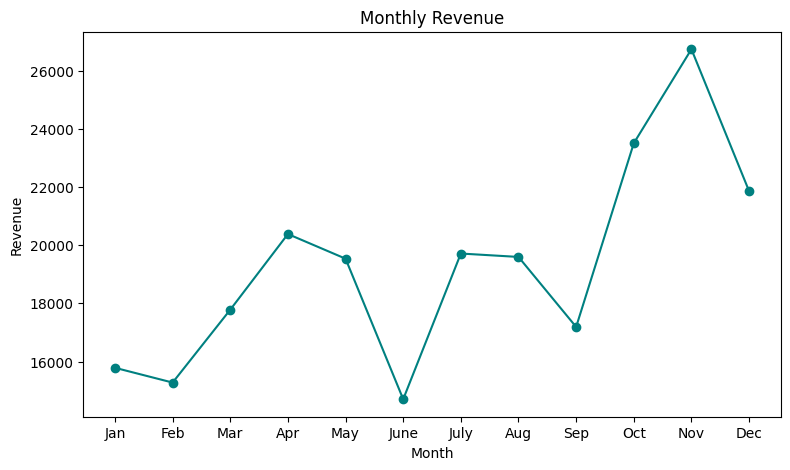

In [40]:
plt.figure(figsize=(9,5))
plt.plot(monthly.index,monthly.values,marker="o",color="teal")
plt.xticks(range(1,13),["Jan","Feb","Mar","Apr","May","June","July","Aug","Sep","Oct","Nov","Dec"])
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.title("Monthly Revenue")
plt.show()

In [41]:
best_category=df.groupby("category")["revenue"].sum().idxmax()
print(f"The best-selling category is {best_category}")

The best-selling category is Electronics


,order_id,date,category,region,quantity,unit_price,discount_pct,customer_age,payment_method,revenue,month
0,1001,2025-12-11,Clothing,South,4,54.79,0,37.0,Wallet,219.16,12
1,1002,2025-08-17,Home,East,2,90.48,10,18.0,UPI,162.86,8
2,1003,2025-09-07,Home,South,5,71.28,15,30.0,Cash,302.94,9
3,1004,2025-11-24,Groceries,West,4,12.18,5,24.0,UPI,46.28,11
4,1005,2025-07-31,Home,South,2,107.08,20,36.0,Card,171.33,7
...,...,...,...,...,...,...,...,...,...,...,...
995,1996,2025-04-25,Home,South,2,80.26,0,27.0,UPI,160.52,4
996,1997,2025-07-17,Electronics,North,2,374.52,0,27.0,Card,749.04,7
997,1998,2025-06-30,Clothing,North,4,42.64,0,62.0,Wallet,170.56,6
998,1999,2025-01-28,Groceries,West,4,15.29,5,40.0,Wallet,58.10,1


<Axes: xlabel='category', ylabel='region'>

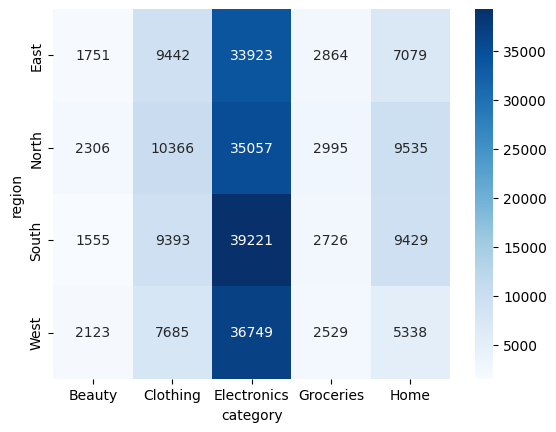

In [44]:
#Task 4
pivot=df.pivot_table(values="revenue",index="region",columns="category",aggfunc="sum")
sns.heatmap(pivot,annot=True,cmap="Blues",fmt=".0f")

<Axes: xlabel='payment_method', ylabel='count'>

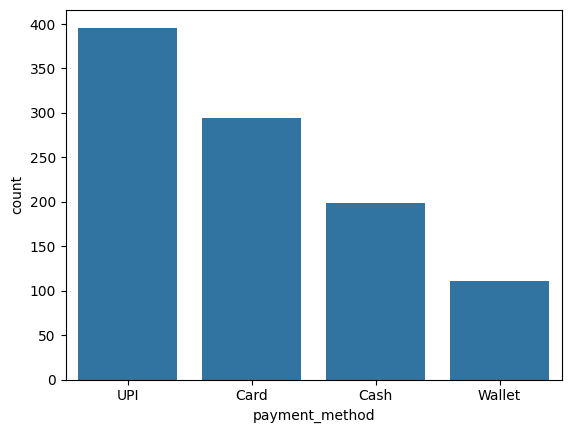

In [45]:
#Task 5
sns.countplot(data=df,x="payment_method",order=df["payment_method"].value_counts().index)

In [47]:
#Task 6 Write a short note on what happens in Nov and Dec.
print(df[df["month"]>=11]["quantity"].mean())
print(df[df["month"]<11]["quantity"].mean())

3.422222222222222
2.953658536585366
